# Dow 30: interactive Brinson attribution

Explore the [MathWorks Brinson workflow](https://www.mathworks.com/help/releases/R2023a/finance/workflow-for-performance-attribution-using-brinson-model.html) using the local `brinsons` library and Yahoo Finance data. Run the cells from top to bottom.

The saved example uses 12 completed months, a **synthetic** portfolio and a monthly rebalanced **equal-weight benchmark**. The benchmark is not the price-weighted Dow index. Current constituents and Yahoo sector classifications are applied to earlier months, so this is not a historical membership backtest. Results exclude fees and transactions.

## 1. Setup

Install the project and notebook dependencies in the active Jupyter kernel if needed: `python -m pip install -e . ipywidgets matplotlib jupyter`. Launch Jupyter from the project root or `tutorials/en/` or `tutorials/zh/`. The default snapshot is read locally and does not make a network request.

To download a new snapshot, first run `python scripts/fetch_dow30.py`, then `python scripts/dow30_brinson_analysis.py` from the project root. This replaces the generated CSV files with a new current-universe snapshot. Rerun the notebook cells afterward.

In [1]:
from pathlib import Path
import sys
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import ipywidgets as widgets
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "brinsons").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the brinson project directory.")
sys.path.insert(0, str(ROOT / "src"))
from brinsons import calculate_multiple_period, bhb, fachler, link_carino, link_grap, link_frongello, link_menchero, link_geometric, chart_multiple_period_excess_return_waterfall

DATA = ROOT / "data" / "dow30_brinson"
asset = pl.read_csv(DATA / "asset_table.csv").sort(["Period", "Name"])
periods = pl.read_csv(DATA / "periods.csv", try_parse_dates=True).sort("Period")
prices = pl.read_csv(DATA / "monthly_prices.csv", try_parse_dates=True)
print(f"{asset['Name'].n_unique()} stocks · {periods.height} periods · {asset['Category'].n_unique()} sectors")
display(periods)

30 stocks · 12 periods · 9 sectors


Period,PeriodStart,PeriodEnd
i64,date,date
1,2025-09-30,2025-10-31
2,2025-10-31,2025-11-28
3,2025-11-28,2025-12-31
4,2025-12-31,2026-01-30
5,2026-01-30,2026-02-27
…,…,…
8,2026-04-30,2026-05-29
9,2026-05-29,2026-06-30
10,2026-06-30,2026-07-31


## 2. Prepare the asset table

The table follows MathWorks: `Period`, `Name`, `Return`, `Category`, `PortfolioWeight`, and `BenchmarkWeight`. Returns are adjusted close-to-close monthly returns. The portfolio target weights and the equal-weight benchmark reset each month; the illustrative target schedule changes every three periods. All numbers are decimals.

In [2]:
expected = ["Period", "Name", "Return", "Category", "PortfolioWeight", "BenchmarkWeight"]
assert asset.columns == expected
price_check = prices.join(periods.select("Period", pl.col("PeriodEnd").alias("date")), on="date").rename({"ticker": "Name"})
joined = asset.join(price_check, on=["Period", "Name"])
assert joined.height == asset.height
assert joined.select((pl.col("Return") - (pl.col("close") / pl.col("previous_close") - 1)).abs().max()).item() < 1e-12
weights = asset.group_by("Period").agg(pl.col("PortfolioWeight", "BenchmarkWeight").sum()).sort("Period")
assert weights.select(((pl.col("PortfolioWeight") - 1).abs() < 1e-10).all()).item()
assert weights.select(((pl.col("BenchmarkWeight") - 1).abs() < 1e-10).all()).item()
display(asset.head(12))

Period,Name,Return,Category,PortfolioWeight,BenchmarkWeight
i64,str,f64,str,f64,f64
1,"""AAPL""",0.061815,"""Technology""",0.032875,0.033333
1,"""AMGN""",0.057512,"""Healthcare""",0.030001,0.033333
1,"""AMZN""",0.112265,"""Consumer Cyclical""",0.031268,0.033333
1,"""AXP""",0.088764,"""Financial Services""",0.035456,0.033333
1,"""BA""",-0.068619,"""Industrials""",0.034092,0.033333
…,…,…,…,…,…
1,"""CSCO""",0.075,"""Technology""",0.036162,0.033333
1,"""CVX""",0.015648,"""Energy""",0.023962,0.033333
1,"""DIS""",-0.016419,"""Communication Services""",0.03324,0.033333


## 3. Calculate attribution

Group asset weights and weighted contributions by period and Yahoo sector, then use `brinsons` to calculate attribution. Selection compares portfolio and benchmark stocks within each sector. Arithmetic linking methods reconcile to the difference of compounded returns; geometric linking has a different multiplicative identity.

The technology multiplier adjusts the example's **initial monthly target weights**, then renormalizes all portfolio weights within each period. It is a what-if scenario using the already observed returns, not a claim that a strategy was actually traded.

In [3]:
ATTRIBUTION = {"Brinson–Fachler": fachler, "Brinson–Hood–Beebower": bhb}
LINKING = {"Menchero": link_menchero, "Cariño": link_carino, "GRAP": link_grap,
           "Frongello": link_frongello, "Geometric": link_geometric}

def calculate(technology_multiplier=1.0, attribution_method="Brinson–Fachler", linking_method="Menchero"):
    adjusted = asset.with_columns(
        (pl.col("PortfolioWeight") * pl.when(pl.col("Category") == "Technology")
         .then(technology_multiplier).otherwise(1.0)).alias("_weight")
    ).with_columns((pl.col("_weight") / pl.col("_weight").sum().over("Period")).alias("PortfolioWeight"))
    category = adjusted.group_by(["Period", "Category"]).agg(
        pl.col("PortfolioWeight").sum().alias("portfolio_weight"),
        pl.col("BenchmarkWeight").sum().alias("benchmark_weight"),
        (pl.col("PortfolioWeight") * pl.col("Return")).sum().alias("p_contribution"),
        (pl.col("BenchmarkWeight") * pl.col("Return")).sum().alias("b_contribution"),
    ).with_columns(
        (pl.col("p_contribution") / pl.col("portfolio_weight")).alias("portfolio_return"),
        (pl.col("b_contribution") / pl.col("benchmark_weight")).alias("benchmark_return"),
    ).rename({"Period": "period", "Category": "segment"}).sort(["period", "segment"])
    workflow = calculate_multiple_period(category.select(
        "period", "segment", "portfolio_weight", "benchmark_weight", "portfolio_return", "benchmark_return"),
        attribution=ATTRIBUTION[attribution_method], linking=LINKING[linking_method])
    result, linked = workflow.periods, workflow.linked
    if linking_method == "Geometric":
        total = linked.summary.row(0, named=True)
        assert abs((1 + total["allocation"]) * (1 + total["selection"]) - 1 - total["excess_return"]) < 1e-10
        sector_effects = None
    else:
        total = linked.summary.row(0, named=True)
        assert abs(total["allocation"] + total["selection"] + total["interaction"] - total["excess_return"]) < 1e-10
        sector_effects = linked.detail.group_by("segment").agg(
            pl.col("linked_allocation", "linked_selection", "linked_interaction").sum()
        ).with_columns(pl.sum_horizontal("linked_allocation", "linked_selection", "linked_interaction").alias("active_effect")).sort("segment")
    return adjusted, category, result, linked, sector_effects

adjusted, category, result, linked, sector_effects = calculate()
print("Full-period attribution (decimal returns) — Linking: Menchero")
display(linked.summary)
print("Periodic sector results")
display(result.detail.head(12))

Full-period attribution (decimal returns) — Linking: Menchero


allocation,selection,interaction,portfolio_return,benchmark_return,excess_return
f64,f64,f64,f64,f64,f64
0.006768,-0.006223,-0.00056,0.143557,0.143573,-0.000016


Periodic sector results


period,segment,portfolio_weight,benchmark_weight,portfolio_return,benchmark_return,allocation,selection,interaction,portfolio_contribution,benchmark_contribution
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""Basic Materials""",0.022769,0.033333,-0.003812,-0.003812,0.00035,0.0,-0.0,-0.000087,-0.000127
1,"""Communication Services""",0.069037,0.066667,0.073338,0.070133,0.000097,0.000214,0.000008,0.005063,0.004676
1,"""Consumer Cyclical""",0.119859,0.133333,-0.010789,-0.010649,0.000538,-0.000019,0.000002,-0.001293,-0.00142
1,"""Consumer Defensive""",0.087666,0.1,0.004122,0.002052,0.000336,0.000207,-0.000026,0.000361,0.000205
1,"""Energy""",0.023962,0.033333,0.015648,0.015648,0.000128,0.0,-0.0,0.000375,0.000522
…,…,…,…,…,…,…,…,…,…,…
1,"""Industrials""",0.124193,0.133333,0.062816,0.058098,-0.000263,0.000629,-0.000043,0.007801,0.007746
1,"""Technology""",0.23341,0.2,0.067329,0.068347,0.001304,-0.000204,-0.000034,0.015715,0.013669
2,"""Basic Materials""",0.022769,0.033333,-0.001295,-0.001295,0.000171,0.0,-0.0,-0.000029,-0.000043


## 4. Compare category returns, weights and attribution

Sector returns below compound each month's within-sector return, with within-sector weights reset monthly. Sector effects are Menchero-linked arithmetic contributions, not the same thing as sector returns.

segment,portfolio_weight,benchmark_weight,portfolio_category_return,benchmark_category_return,linked_allocation,linked_selection,linked_interaction,active_effect
str,f64,f64,f64,f64,f64,f64,f64,f64
"""Basic Materials""",0.02583,0.033333,-0.057539,-0.057539,0.002081,-2.7786e-19,8.8064e-20,0.002081
"""Communication Services""",0.065103,0.066667,0.170686,0.172176,0.000242,-0.000028,-0.000014,0.0002
"""Consumer Cyclical""",0.12357,0.133333,-0.215466,-0.216581,0.00406,0.000085,-0.000083,0.004061
"""Consumer Defensive""",0.084258,0.1,0.113609,0.103414,-0.001202,0.001105,-0.000114,-0.000211
"""Energy""",0.023921,0.033333,0.366842,0.366842,0.000636,0.0,0.0,0.000636
"""Financial Services""",0.172935,0.166667,0.103518,0.105832,-0.000332,-0.000404,-0.000062,-0.000797
"""Healthcare""",0.137498,0.133333,0.455508,0.486286,0.001672,-0.003357,-0.000013,-0.001699
"""Industrials""",0.124008,0.133333,0.165641,0.178434,-0.000794,-0.001642,0.000014,-0.002422
"""Technology""",0.242877,0.2,0.161861,0.171908,0.000406,-0.001983,-0.000288,-0.001865


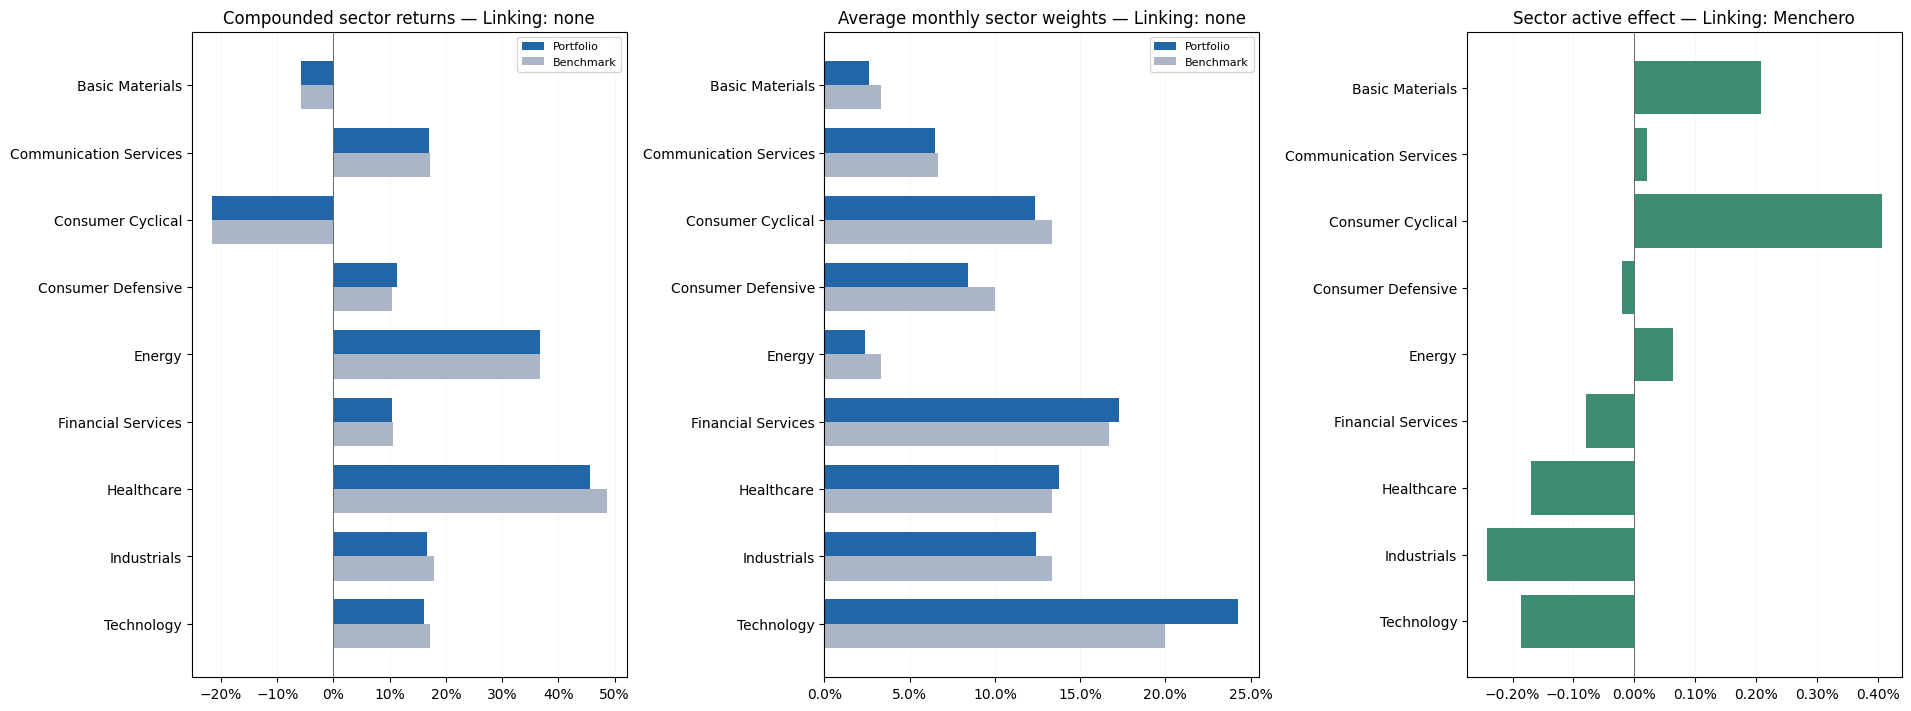

In [4]:
category_summary = category.group_by("segment").agg(
    pl.col("portfolio_weight", "benchmark_weight").mean(),
    ((1 + pl.col("portfolio_return")).product() - 1).alias("portfolio_category_return"),
    ((1 + pl.col("benchmark_return")).product() - 1).alias("benchmark_category_return"),
).join(sector_effects, on="segment").sort("segment")
display(category_summary)
labels = category_summary["segment"].to_list()
y = list(range(len(labels)))
fig, axes = plt.subplots(1, 3, figsize=(19, 7), layout="constrained")
for ax, pcol, bcol, title in [
    (axes[0], "portfolio_category_return", "benchmark_category_return", "Compounded sector returns — Linking: none"),
    (axes[1], "portfolio_weight", "benchmark_weight", "Average monthly sector weights — Linking: none"),
]:
    ax.barh([i - .18 for i in y], category_summary[pcol].to_list(), height=.36, label="Portfolio", color="#2366a8")
    ax.barh([i + .18 for i in y], category_summary[bcol].to_list(), height=.36, label="Benchmark", color="#aab5c5")
    ax.set_title(title); ax.set_yticks(y, labels); ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.legend(fontsize=8)
axes[2].barh(y, category_summary["active_effect"].to_list(), color="#3f8d70")
axes[2].set(title="Sector active effect — Linking: Menchero", yticks=y, yticklabels=labels)
axes[2].invert_yaxis(); axes[2].xaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.axvline(0, color="#666666", lw=.7); ax.grid(axis="x", color="#e6e9ed"); ax.set_axisbelow(True)
plt.show()

## 5. Interactive exploration

Change the technology multiplier, attribution or linker to recalculate the full horizon. Select a sector and period to inspect monthly weights, returns and effects. Geometric linking reports geometric active return; its two effects combine multiplicatively and do not produce additive linked sector effects in this library.
The aggregate excess-return waterfall follows the selected linking method. For geometric linking it shows allocation, selection, their cross term, and relative active return.


In [5]:
method_control = widgets.Dropdown(options=list(ATTRIBUTION), value="Brinson–Fachler", description="Attribution:")
link_control = widgets.Dropdown(options=list(LINKING), value="Menchero", description="Linking:")
tilt_control = widgets.FloatSlider(value=1.0, min=0.5, max=1.5, step=0.05, description="Tech tilt:", continuous_update=False, readout_format=".2f")
period_control = widgets.IntSlider(value=1, min=int(periods["Period"].min()), max=int(periods["Period"].max()), step=1, description="Period:", continuous_update=False)
sector_control = widgets.Dropdown(options=sorted(asset["Category"].unique().to_list()), description="Sector:")

def explore(attribution_method, linking_method, technology_multiplier, period, sector):
    _, cats, per, linked_result, effects = calculate(technology_multiplier, attribution_method, linking_method)
    total = linked_result.summary.row(0, named=True)
    print(f"Multiple-period linking method: {linking_method}")
    kind = "Geometric active return" if linking_method == "Geometric" else "Arithmetic active return"
    print(f"Portfolio: {total['portfolio_return']:.4%}   Benchmark: {total['benchmark_return']:.4%}   {kind}: {total['excess_return']:.4%}")
    print(f"Allocation: {total['allocation']:.4%}   Selection: {total['selection']:.4%}   Interaction: {total['interaction']:.4%}")
    print("Selected sector and period (decimal returns and weights):")
    display(per.detail.filter((pl.col("period") == period) & (pl.col("segment") == sector)).select(
        "period", "segment", "portfolio_weight", "benchmark_weight", "portfolio_return", "benchmark_return", "allocation", "selection", "interaction"))
    timeline = cats.filter(pl.col("segment") == sector).sort("period")
    fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
    ax.plot(timeline["period"].to_list(), timeline["portfolio_return"].to_list(), marker="o", label="Portfolio")
    ax.plot(timeline["period"].to_list(), timeline["benchmark_return"].to_list(), marker="o", label="Benchmark")
    ax.axvline(period, color="#888888", linestyle="--", linewidth=.8)
    ax.axhline(0, color="#777777", linewidth=.7); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f"{sector}: periodic sector returns — Linking: none", xlabel="Period", ylabel="Return")
    ax.grid(alpha=.2); ax.legend(); plt.show()
    fig, ax = chart_multiple_period_excess_return_waterfall(
        per, by_category=False, linking=LINKING[linking_method])
    plt.show()
    if effects is not None:
        print(f"Linked sector effects (decimal returns) — Linking: {linking_method}")
        display(effects.filter(pl.col("segment") == sector))

controls = widgets.VBox([widgets.HBox([method_control, link_control]), tilt_control,
                        widgets.HBox([period_control, sector_control])])
output = widgets.interactive_output(explore, {"attribution_method": method_control, "linking_method": link_control,
    "technology_multiplier": tilt_control, "period": period_control, "sector": sector_control})
display(controls, output)

Output()

## Sources and interpretation

- Source inputs: Yahoo Finance adjusted closes and Yahoo sector labels from the snapshot generated by the local scripts.
- Workbook and detailed methodology: `outputs/dow30_brinson/Dow30_brinson_analysis.xlsx` and `outputs/dow30_brinson/analysis.md`.
- Attribution convention: Brinson–Fachler or BHB; linking is selected above. GRAP and Frongello use equivalent factors in this implementation.
- Classification and constituent membership are a current snapshot; results are hypothetical, not investment advice or proof of skill.